# Video-based Human Action Quality Assessment: AQA-7 Diving

**What this notebook does:** It tries to predict the score that judges gave to a dive, using only the video. It covers the whole technical assessment:

| Part | What it does | Brief |
|---|---|---|
| 1 | Looks at the data and creates the train / validation / test split | Task 2A |
| 2 | Turns every video into numbers features with a pretrained video network | Task 2B |
| 3 | Trains a simple baseline and four temporal models, and evaluates them | Tasks 2B–2D |
| 4 | One controlled experiment: do the temporal models really beat the baseline? | Task 3 (Option A) |

**How to run it:** On Kaggle (GPU accelerator, **Internet ON**, AQA-7 dataset attached) or locally (Python with a GPU recommended, Internet needed once to download the I3D model). The README gives both set-ups step by step. Before running, set `ROOT` (and `OUT` if not on Kaggle) in the first code cell of Part 1. Then run all cells from top to bottom. Slow steps save their results in the output folder and are skipped on the next run.

**Reproducibility:** Every random step uses a fixed seed. The seeds are listed in the cells where they are used.


# Part 1 · Data exploration: AQA-7 Diving

**Goal:** understand the data before building any model: how many videos, what they look like, how the scores are spread, and what could make the task hard.

**Data:** AQA-7 (Parmar & Morris, WACV 2019) contains 7 sports. We use only **action class ,diving**, with the official split lists of the dataset.

**Output:** `diving_splits.csv`, the list of clips with their score and split. Every later part reads this file.

### Setup
This cell loads the Python libraries, sets the fixed seed (`SEED = 42`) and two paths:
- `ROOT` = the AQA-7 dataset folder (the one that contains `Actions/` and `Split_4/`). **Change it to your own path**, on Kaggle or on your computer.
- `OUT` = where all results are saved. `/kaggle/working` on Kaggle; on your own computer use any folder.

`VAL_FRAC = 0.20` means 20 % of the official training clips will be kept aside for validation.

In [1]:
import os, json, platform
import numpy as np, pandas as pd, scipy.io as sio, scipy.stats as st
import matplotlib.pyplot as plt
import cv2

SEED = 42
ROOT = "/kaggle/input/datasets/yasminecharradi/aqa-7-sportssss/AQA-7"   # change this to your own path to the AQA-7 folder
OUT  = "/kaggle/working"                                                 # where results are saved 
VIDEO_DIR = os.path.join(ROOT, "Actions", "diving")
VAL_FRAC = 0.20          
os.makedirs(OUT, exist_ok=True)

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", __import__('scipy').__version__, "| opencv", cv2.__version__)

python 3.13.15 | numpy 2.1.3 | pandas 2.3.3 | scipy 1.16.3 | opencv 4.14.0


## 1.1 Load the official train and test lists (diving only)
The dataset gives two `.mat` files: one for train, one for test. Each row has 3 numbers: `action` (1 = diving), `sample` the video number and `score` (the judges' final score).

The cell keeps the diving rows only and checks three things: no clip is listed twice, no clip is in both train and test, and every video file exists. `official` says which official list a clip comes from.

In [2]:
def load_list(fname, key):
    m = sio.loadmat(os.path.join(ROOT, "Split_4", fname))[key]
    df = pd.DataFrame(m, columns=["action", "sample", "score"])
    df[["action", "sample"]] = df[["action", "sample"]].astype(int)
    return df[df.action == 1].drop(columns="action").reset_index(drop=True)

tr = load_list("split_4_train_list.mat", "consolidated_train_list"); tr["official"] = "train"
te = load_list("split_4_test_list.mat",  "consolidated_test_list");  te["official"] = "test"
df = pd.concat([tr, te], ignore_index=True)
df["video"] = df["sample"].map(lambda s: os.path.join(VIDEO_DIR, f"{s:03d}.avi"))

assert tr["sample"].is_unique and te["sample"].is_unique, "duplicate samples in a list"
assert not set(tr["sample"]) & set(te["sample"]), "train/test overlap"
assert df["video"].map(os.path.exists).all(), "missing video files"
n_videos = len([f for f in os.listdir(VIDEO_DIR) if f.endswith('.avi')])
print(f"train {len(tr)} | test {len(te)} | total listed {len(df)} | videos on disk {n_videos}")
print("sample numbers range:", df['sample'].min(), "-", df['sample'].max())
df.head()

train 300 | test 70 | total listed 370 | videos on disk 370
sample numbers range: 1 - 370


,sample,score,official,video
0,54,84.15,train,/kaggle/input/datasets/yasminecharradi/aqa-7-s...
1,341,74.25,train,/kaggle/input/datasets/yasminecharradi/aqa-7-s...
2,41,97.20,train,/kaggle/input/datasets/yasminecharradi/aqa-7-s...
3,30,83.25,train,/kaggle/input/datasets/yasminecharradi/aqa-7-s...
4,144,102.60,train,/kaggle/input/datasets/yasminecharradi/aqa-7-s...


## 1.2 Video properties
We open every video and check the number of frames (`n_frames`), the frame rate (`fps`, frames per second) and the image size (`width` × `height` in pixels). Part 2 relies on these values.

In [3]:
def video_meta(path):
    cap = cv2.VideoCapture(path)
    n_prop = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n_read = 0                                   
    while cap.grab(): n_read += 1
    cap.release()
    return n_prop, n_read, fps, w, h

meta = pd.DataFrame([video_meta(p) for p in df.video], columns=["n_prop", "n_frames", "fps", "width", "height"])
df = pd.concat([df, meta], axis=1)
print(df[["n_frames", "fps", "width", "height"]].describe().T[["min", "max", "mean"]])
print("\nframe-count values:", df.n_frames.value_counts().to_dict())
print("resolutions:", df.groupby(["width", "height"]).size().to_dict())

            min    max   mean
n_frames  103.0  103.0  103.0
fps        30.0   30.0   30.0
width     320.0  320.0  320.0
height    240.0  240.0  240.0

frame-count values: {103: 370}
resolutions: {(320, 240): 370}


## 1.3 Score distribution
**How a dive is scored:** final score = difficulty of the dive (DD, fixed by the dive chosen) × sum of the judges' marks for execution. The dataset gives **only the final score**, so we can't separate "hard dive" from "well-executed dive", a point I will come back to in task 4.

The table describes the scores of each split. Columns: `q25` / `q75` = the values below which 25 % / 75 % of scores fall; `skew` = how lopsided the distribution is (negative = a long tail of low scores); `excess_kurtosis` = how heavy the tails are (> 0 = more extreme values than a bell curve); `n_unique` = number of different score values.

It also prints a **KS test**, which checks whether train and test scores follow the same distribution (a large p-value, e.g. > 0.05, means no sign of a difference), and how many clips share exactly the same score ("ties").

In [4]:
def describe(s):
    return pd.Series({"n": len(s), "mean": s.mean(), "std": s.std(), "min": s.min(), "q25": s.quantile(.25),
                      "median": s.median(), "q75": s.quantile(.75), "max": s.max(),
                      "skew": st.skew(s), "excess_kurtosis": st.kurtosis(s), "n_unique": s.nunique()})

stats = pd.DataFrame({k: describe(g.score) for k, g in df.groupby("official")}).T
stats.loc["all"] = describe(df.score)
display(stats.round(2))

ks = st.ks_2samp(tr.score, te.score)
print(f"KS test train vs test scores: D={ks.statistic:.3f}, p={ks.pvalue:.3f}")
ties = df.score.value_counts()
print(f"scores shared by >1 clip: {(ties > 1).sum()} values covering {ties[ties > 1].sum()} clips (ties matter for Spearman)")

,n,mean,std,min,q25,median,q75,max,skew,excess_kurtosis,n_unique
test,70.0,77.60,15.66,21.6,72.00,80.4,86.4,102.6,-1.35,2.10,50.0
train,300.0,78.88,13.98,29.7,72.57,81.5,88.8,102.6,-1.17,1.43,109.0
all,370.0,78.64,14.30,21.6,72.00,81.2,88.8,102.6,-1.23,1.68,121.0


KS test train vs test scores: D=0.058, p=0.984
scores shared by >1 clip: 65 values covering 314 clips (ties matter for Spearman)


### Score plots
- **Left:** histogram of scores for train and test (how many dives get each score).
- **Middle:** cumulative curve: for each score, the share of dives scoring at most that much. If the two curves overlap, train and test look alike.
- **Right:** score against video number (red = test), to check whether scores follow some order in the file numbering.

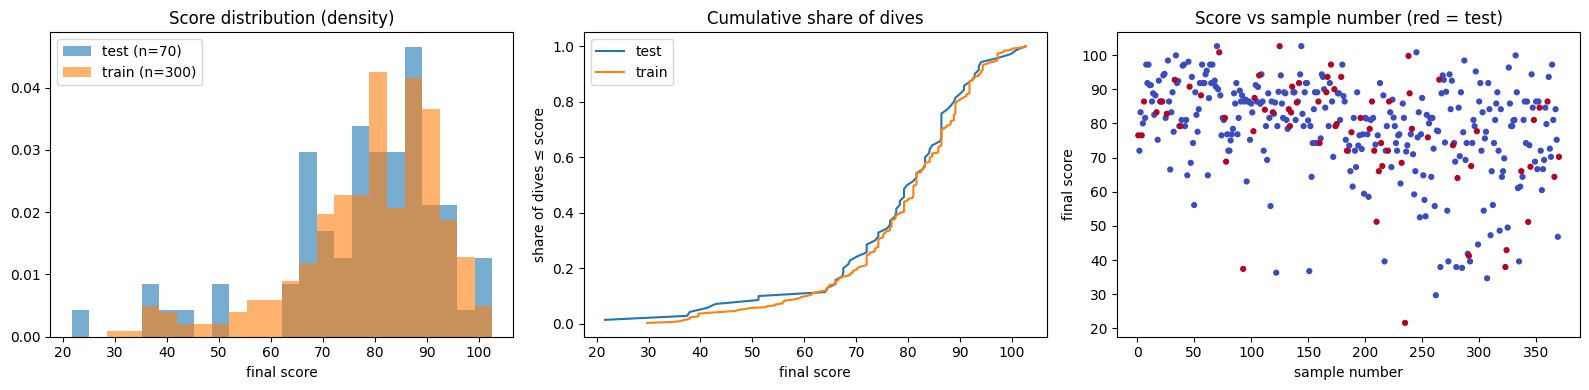

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
bins = np.linspace(df.score.min(), df.score.max(), 25)
for k, g in df.groupby("official"):
    ax[0].hist(g.score, bins=bins, alpha=.6, density=True, label=f"{k} (n={len(g)})")
ax[0].set(title="Score distribution (density)", xlabel="final score"); ax[0].legend()

for k, g in df.groupby("official"):
    x = np.sort(g.score); ax[1].plot(x, np.arange(1, len(x) + 1) / len(x), label=k)
ax[1].set(title="Cumulative share of dives", xlabel="final score", ylabel="share of dives ≤ score"); ax[1].legend()

ax[2].scatter(df["sample"], df.score, c=(df.official == "test"), cmap="coolwarm", s=12)
ax[2].set(title="Score vs sample number (red = test)", xlabel="sample number", ylabel="final score")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_score_distribution.png", dpi=150); plt.show()

### How unbalanced are the scores?


In [6]:
edges = [0, 40, 50, 60, 70, 80, 90, 200]
counts = pd.crosstab(pd.cut(df.score, edges), df.official)
counts["share_%"] = (100 * counts.sum(axis=1) / len(df)).round(1)
counts

official,test,train,share_%
score,,,
"(0, 40]",3,11,3.8
"(40, 50]",2,6,2.2
"(50, 60]",2,12,3.8
"(60, 70]",9,29,10.3
"(70, 80]",19,77,25.9
"(80, 90]",23,108,35.4
"(90, 200]",12,57,18.6


## 1.4 Do the three parts of a clip match take-off, flight and entry?
In Part 2, each clip is cut into **9 short pieces ("snippets") of 16 frames**, starting every 10 frames (frames 0–15, 10–25, …, 80–95), as in the FineDiving paper. One model in Part 3 (`seg3`) groups them into **3 thirds**: frames **0–35, 30–65, 60–95**, hoping these match the 3 phases of a dive (take-off, flight, entry into the water).

The dataset has no labels for these phases, so this is only a **guess to check by eye**. The cell prints the frame ranges, then shows 8 frames from 5 dives (from the lowest to the highest score). Each picture is titled with its frame number (`f`) and the third it belongs to (`seg`). The number on the left is the video number and its score.

snippets: [(0, 15), (10, 25), (20, 35), (30, 45), (40, 55), (50, 65), (60, 75), (70, 85), (80, 95)]
segments (frame ranges): [(0, 35), (30, 65), (60, 95)]
frames never used by any snippet: [96, 97, 98, 99, 100, 101, 102]


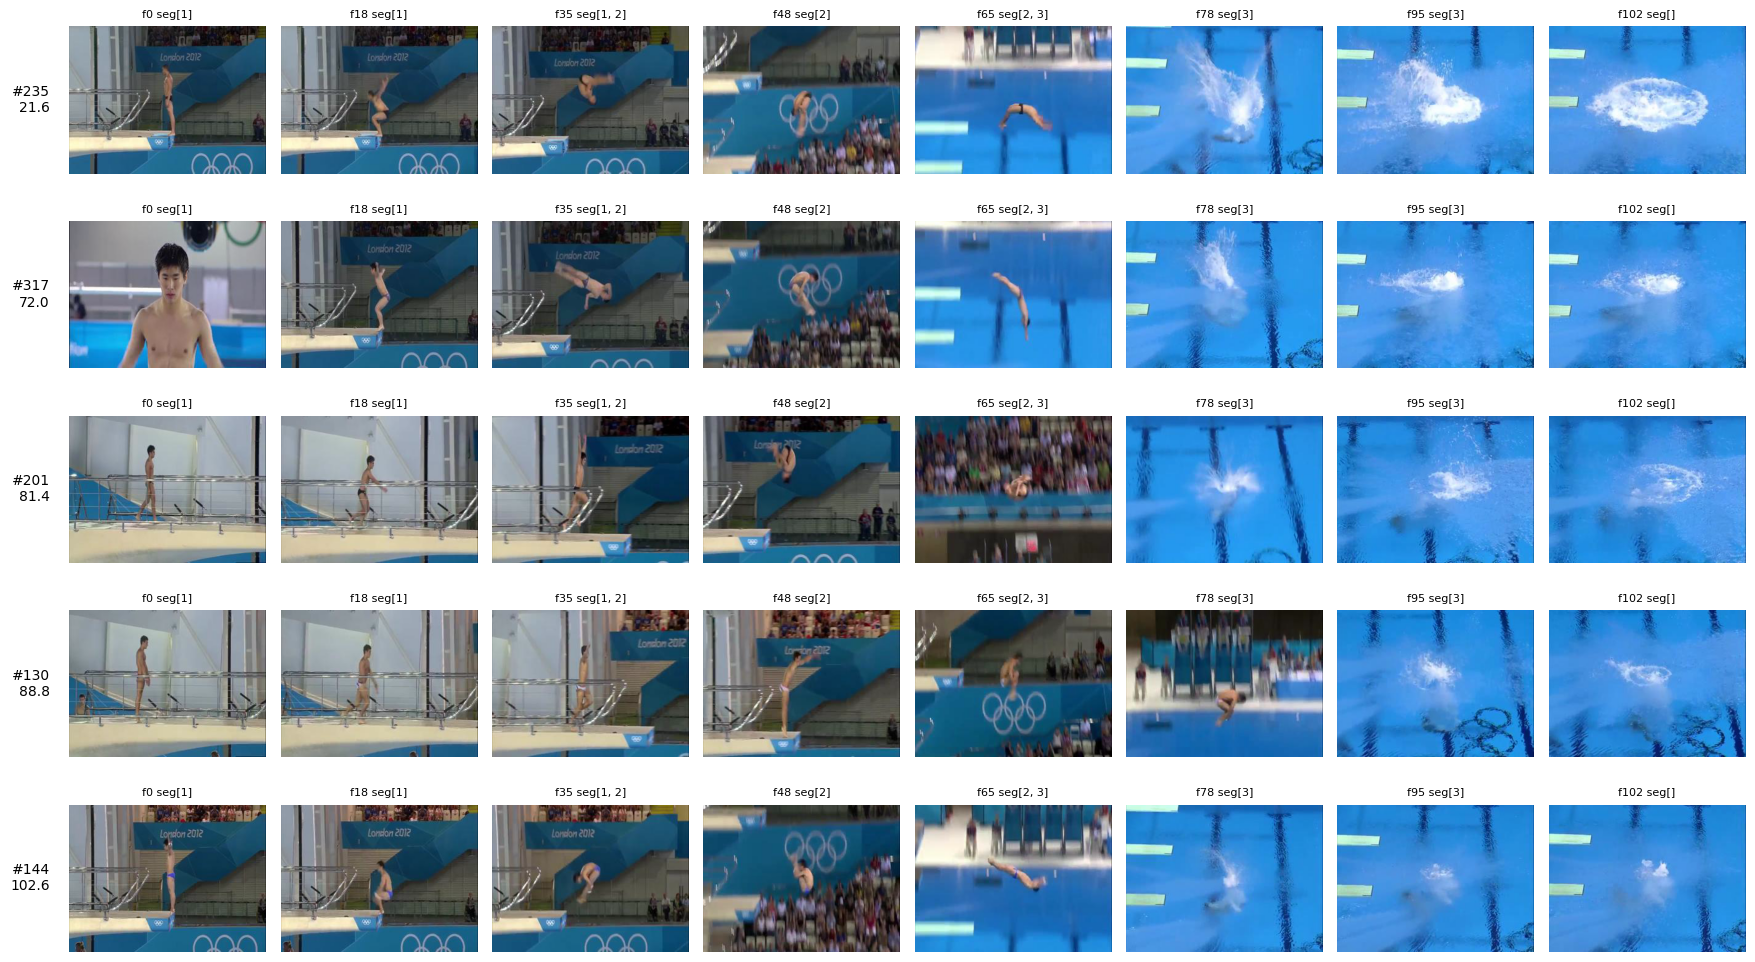

In [7]:
SNIPPET_LEN, STRIDE, N_SNIPPETS = 16, 10, 9
snippets = [(i * STRIDE, i * STRIDE + SNIPPET_LEN - 1) for i in range(N_SNIPPETS)]
segments = [(snippets[3 * j][0], snippets[3 * j + 2][1]) for j in range(3)]
print("snippets:", snippets); print("segments (frame ranges):", segments)
print("frames never used by any snippet:", sorted(set(range(df.n_frames.min())) - {f for a, b in snippets for f in range(a, b + 1)}))

def read_frames(path, idx):
    cap, out, i, want = cv2.VideoCapture(path), {}, 0, set(idx)
    while True:
        ok, fr = cap.read()
        if not ok: break
        if i in want: out[i] = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
        i += 1
    cap.release(); return [out.get(j) for j in idx]

show_idx = [0, 18, 35, 48, 65, 78, 95, 102]
picks = df.sort_values("score").iloc[[0, len(df) // 4, len(df) // 2, 3 * len(df) // 4, -1]]
fig, axes = plt.subplots(len(picks), len(show_idx), figsize=(2.2 * len(show_idx), 2 * len(picks)))
for r, (_, row) in enumerate(picks.iterrows()):
    for c, (j, fr) in enumerate(zip(show_idx, read_frames(row.video, show_idx))):
        ax = axes[r, c]; ax.axis("off")
        if fr is not None: ax.imshow(fr)
        seg = [k + 1 for k, (a, b) in enumerate(segments) if a <= j <= b]
        ax.set_title(f"f{j} seg{seg}", fontsize=8)
    axes[r, 0].text(-0.1, 0.5, f"#{row['sample']}\n{row.score:.1f}", transform=axes[r, 0].transAxes, ha="right", va="center")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_frames_vs_segments.png", dpi=120); plt.show()

## 1.5 Train / validation / test split
- **Test (70 clips):** the official test list. 
- **Validation (60 clips):** 20 % of the official train list. Used to choose model settings and when to stop training.
- **Train (240 clips):** the rest of the official train list. The models learn from these.

**How validation is chosen:** we sort the 300 training clips by score and take every 5th one (the starting point is picked with the fixed seed). This guarantees validation contains low, medium and high scores. (A first version, which sampled within score groups, left no validation clip below 52.8 and was replaced.)

The cell prints the size and score statistics of each split, a KS test train vs validation (similar by construction), and saves `diving_splits.csv` plus `diving_splits_meta.json` (how the split was made).

In [8]:
rng = np.random.default_rng(SEED)
trn = df[df.official == "train"].sort_values(["score", "sample"])   
k = int(round(1 / VAL_FRAC))                                        
offset = int(rng.integers(k))
val_idx = trn.index[offset::k]
df["split"] = df.official
df.loc[val_idx, "split"] = "val"

print(df.split.value_counts().to_dict())
display(df.groupby("split").score.describe().round(2))
print("KS train vs val:", st.ks_2samp(df[df.split == 'train'].score, df[df.split == 'val'].score))

cols = ["sample", "score", "split", "official", "n_frames", "fps", "width", "height", "video"]
df[cols].sort_values(["split", "sample"]).to_csv(f"{OUT}/diving_splits.csv", index=False)
json.dump({"seed": SEED, "val_frac": VAL_FRAC, "stratify": "systematic sampling (every k-th) over score-sorted official train, random offset",
           "counts": df.split.value_counts().to_dict()}, open(f"{OUT}/diving_splits_meta.json", "w"), indent=2)
print("saved", f"{OUT}/diving_splits.csv")

{'train': 240, 'test': 70, 'val': 60}


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,70.0,77.60,15.66,21.60,72.00,80.4,86.40,102.6
train,240.0,79.02,13.82,34.65,72.57,81.5,88.88,102.6
val,60.0,78.34,14.71,29.70,72.45,81.3,88.80,99.9


KS train vs val: KstestResult(statistic=np.float64(0.016666666666666666), pvalue=np.float64(1.0), statistic_location=np.float64(85.8), statistic_sign=np.int8(-1))
saved /kaggle/working/diving_splits.csv


## 1.6 What we observed, and the challenges it creates
**Observed** (from the outputs above):
- 370 diving clips: 300 official train, 70 official test. No duplicates, no overlap, no missing video.
- Every clip has **103 frames at 30 fps, 320×240 pixels** (about 3.4 s).
- Scores: mean 78.6, median 81.2, std 14.3, range 21.6–102.6. **61 % of dives score between 70 and 90**, and only **9.8 % (36 clips) score 60 or less**. The distribution has a long tail of low scores (skew −1.23).
- Only 121 different score values for 370 clips: 85 % of clips share their score with at least one other clip.
- Train and test scores look alike (KS D = 0.058, p = 0.98).
- Final split: train 240 (scores 34.7–102.6), validation 60 (29.7–99.9), test 70 (21.6–102.6).
- The thirds only roughly match the phases: one dive is still in the air at frame 78 while others have already entered the water.

**Challenges for the models:**
1. **Very small dataset:** 240 clips to learn from, 70 to test. Models can overfit, and test numbers are uncertain (so Part 3 reports CI95).
2. **Unbalanced scores:** most dives are between 70 and 90. A model can get a fairly low error by predicting about 80 for everything, and will tend to over-predict the rare bad dives. That is why we also compare against a model that always predicts the average, and look at errors per score range.
3. **Difficulty and execution are mixed:** only the final score is given, so a model may learn "which dive is hard" instead of "how well it was done" (this motivates the research proposal).
4. **Fixed-length clips:** all clips have 103 frames, but the phases don't happen at the same frame in every dive, so fixed thirds are only an approximation.
5. **Many tied scores:** Spearman ρ gives tied dives the same average rank, so tiny differences between them don't count.


# Part 2 · Turning videos into numbers with a pretrained I3D network

We use a pretrained video network that has already learned to recognise actions from a large dataset. We keep its weights frozen and use it to extract features.

Every model in Part 3 then uses exactly the same features, so any difference between models comes from the model itself, not from the video encoder.

**The network:** **I3D** (Carreira & Zisserman, CVPR 2017). We use the PyTorch version by piergiaj (`pytorch_i3d.py`, weights `rgb_imagenet.pt`). The FineDiving paper uses the same family of network.

**What comes out, per clip (as in FineDiving):** frames 0–95 → **9 snippets of 16 frames** (one every 10 frames) → I3D gives **1024 numbers per snippet** → an array of shape **(9, 1024)**: 9 moments in time × 1024 numbers.

**Requirements:** a GPU is recommended and internet access the first time to download I3D. Output folder: `features/` inside the output folder `OUT` (see Part 1).

### Setup


In [9]:
import os, sys, time, hashlib, urllib.request
import numpy as np, pandas as pd, cv2, torch

SEED = 42
# OUT (the results folder) was set in Part 1
FEAT_DIR = os.path.join(OUT, "features"); os.makedirs(FEAT_DIR, exist_ok=True)
SPLITS_CSV = os.path.join(OUT, "diving_splits.csv")          
SNIPPET_LEN, STRIDE, N_SNIPPETS = 16, 10, 9
RESIZE_SHORT, CROP = 256, 224
BATCH_CLIPS = 4                                              

torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

torch 2.11.0+cu128 | device cuda | Tesla T4


## 2.1 Download the I3D code and weights


In [10]:
I3D_DIR = os.path.join(OUT, "i3d"); os.makedirs(I3D_DIR, exist_ok=True)
FILES = {
    "pytorch_i3d.py":   "https://raw.githubusercontent.com/piergiaj/pytorch-i3d/master/pytorch_i3d.py",
    "rgb_imagenet.pt":  "https://github.com/piergiaj/pytorch-i3d/raw/master/models/rgb_imagenet.pt",
}
for name, url in FILES.items():
    path = os.path.join(I3D_DIR, name)
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    sha = hashlib.sha256(open(path, "rb").read()).hexdigest()
    print(f"{name:16s} {os.path.getsize(path)/1e6:7.2f} MB  sha256={sha}")

sys.path.insert(0, I3D_DIR)
from pytorch_i3d import InceptionI3d

i3d = InceptionI3d(num_classes=400, in_channels=3)
state = torch.load(os.path.join(I3D_DIR, "rgb_imagenet.pt"), map_location="cpu")
print(i3d.load_state_dict(state, strict=True))               # must print: <All keys matched successfully>
i3d = i3d.to(DEVICE).eval()
for p in i3d.parameters(): p.requires_grad_(False)
print("I3D parameters (frozen):", sum(p.numel() for p in i3d.parameters()) / 1e6, "M")

pytorch_i3d.py      0.01 MB  sha256=c322c3ca015dab5ee43e4d15707149d510b98931406c4a5d58b27934ed6777ed
rgb_imagenet.pt    50.88 MB  sha256=2609088c2e8c868187c9921c50bc225329a9057ed75e76120e0b4a397a2c7538
<All keys matched successfully>
I3D parameters (frozen): 12.697264 M


## 2.2 From a video file to I3D features
Three small functions:
- `load_clip`: reads all frames of a video, resizes each frame so its short side is 256 pixels, and keeps the central 224×224 square (the input size I3D expects). Always the centre, so the result is the same every time.
- `clip_to_snippets`: scales pixel values from 0..255 to −1…1 (what this I3D version expects) and cuts the 9 snippets of 16 frames.
- `encode`: passes snippets through I3D and returns 1024 numbers per snippet.

The cell then tests them on one clip and prints the shapes: `(9, 3, 16, 224, 224)` = 9 snippets × 3 colours × 16 frames × 224 × 224 pixels, and `(9, 1024)` for the features.

In [11]:
def load_clip(path):
    """Return uint8 array (T, CROP, CROP, 3) RGB, short side resized to RESIZE_SHORT then centre-cropped."""
    cap, frames = cv2.VideoCapture(path), []
    while True:
        ok, fr = cap.read()
        if not ok: break
        h, w = fr.shape[:2]; s = RESIZE_SHORT / min(h, w)
        fr = cv2.resize(fr, (round(w * s), round(h * s)), interpolation=cv2.INTER_LINEAR)
        h, w = fr.shape[:2]; y, x = (h - CROP) // 2, (w - CROP) // 2
        frames.append(cv2.cvtColor(fr[y:y + CROP, x:x + CROP], cv2.COLOR_BGR2RGB))
    cap.release()
    return np.stack(frames)

NEEDED = (N_SNIPPETS - 1) * STRIDE + SNIPPET_LEN             # 96 frames
SNIPPET_STARTS = [i * STRIDE for i in range(N_SNIPPETS)]

def clip_to_snippets(frames):
    """(T,H,W,3) uint8 -> float tensor (N_SNIPPETS, 3, SNIPPET_LEN, H, W) in [-1, 1]."""
    assert len(frames) >= NEEDED, f"clip has {len(frames)} frames, need {NEEDED}"
    x = torch.from_numpy(frames).float().div_(127.5).sub_(1.0)         # [-1, 1]
    x = x.permute(3, 0, 1, 2)                                          
    return torch.stack([x[:, s:s + SNIPPET_LEN] for s in SNIPPET_STARTS])

@torch.no_grad()
def encode(snips):
    """(N, 3, 16, 224, 224) -> (N, 1024)."""
    f = i3d.extract_features(snips.to(DEVICE))                         
    return f.flatten(1).cpu()

splits = pd.read_csv(SPLITS_CSV).sort_values("sample").reset_index(drop=True)  
x = clip_to_snippets(load_clip(splits.video.iloc[0]))
print("snippet tensor:", tuple(x.shape), "range", (x.min().item(), x.max().item()))
print("feature shape for one clip:", tuple(encode(x).shape))

snippet tensor: (9, 3, 16, 224, 224) range (-1.0, 1.0)
feature shape for one clip: (9, 1024)


## 2.3 Extract and save the features of all 370 clips


In [12]:
FEAT_PATH = os.path.join(FEAT_DIR, "i3d_diving_9x1024.npy")
IDS_PATH  = os.path.join(FEAT_DIR, "i3d_diving_samples.npy")

if os.path.exists(FEAT_PATH) and os.path.exists(IDS_PATH):
    print("cache found, skipping extraction")
else:
    samples = splits["sample"].to_numpy()
    feats = np.zeros((len(samples), N_SNIPPETS, 1024), dtype=np.float32)
    t0 = time.time()
    for b in range(0, len(samples), BATCH_CLIPS):
        rows = splits.iloc[b:b + BATCH_CLIPS]
        snips = torch.cat([clip_to_snippets(load_clip(p)) for p in rows.video])
        feats[b:b + len(rows)] = encode(snips).view(len(rows), N_SNIPPETS, 1024).numpy()
        if (b // BATCH_CLIPS) % 10 == 0:
            print(f"{b + len(rows):4d}/{len(samples)} clips  {time.time() - t0:6.1f}s")
    np.save(FEAT_PATH, feats); np.save(IDS_PATH, samples)
    print(f"done in {time.time() - t0:.1f}s ->", FEAT_PATH)

   4/370 clips     1.7s
  44/370 clips    18.5s
  84/370 clips    35.0s
 124/370 clips    51.7s
 164/370 clips    68.7s
 204/370 clips    85.8s
 244/370 clips   103.1s
 284/370 clips   120.6s
 324/370 clips   138.5s
 364/370 clips   156.6s
done in 159.3s -> /kaggle/working/features/i3d_diving_9x1024.npy


# Part 3 · A baseline and four temporal models

**Goal:** predict the score of a dive from its (9, 1024) features, and find out whether using the **order in time** of the 9 snippets helps.

**One controlled comparison.** All neural models have the same 3 steps, and **only the middle step changes**:

`9 snippets × 1024 numbers` → **(1) projection:** each snippet is compressed to `d` numbers → **(2) aggregator:** the 9 snippets are combined into one vector → **(3) head:** a small network turns that vector into one score.

| Model | What the aggregator does | Uses the order of snippets? |
|---|---|---|
| `avgpool` (**baseline**) | simple average of the 9 snippets (the "global" representation) | no |
| `seg3` | average within each third (take-off / flight / entry), then combine the 3 | roughly (3 phases) |
| `tcn` | temporal convolution: looks at each snippet together with its neighbours | yes (locally) |
| `gru` | recurrent network: reads the snippets one after the other, forwards and backwards | yes |
| `attn` | attention: learns a weight for each snippet and takes a weighted average; a learned "position" signal tells it which snippet is which | yes (through positions) |

Without the position signal, `attn` would ignore order (shuffling the snippets would give the same result), so it would not be a temporal model.

**Two simple reference points** (not neural networks):
- `R0_mean_predictor`: always predicts the average training score (about 79). Any useful model must have a lower MAE. Its ρ is undefined (it gives every dive the same score, so it cannot rank them).
- `R1_ridge`: a linear regression on the averaged features.

**Same rules for every model:**
- Train on 240 clips, choose settings on the 60 validation clips, test once on the 70 test clips.
- Features and scores are standardised (shifted and scaled using train statistics only). Loss = mean squared error.
- **Choosing settings (validation only):** 8 combinations of settings × 3 seeds per model; we keep the combination with the best average validation ρ. Training also stops when validation ρ stops improving.
- **Final runs:** the chosen settings are retrained with 5 *new* seeds, and only then is the test set used, once per model.
- Metrics: Spearman ρ and MAE.

### Setup


In [13]:
import os, json, time, itertools, copy, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
import sklearn

# OUT (the results folder) was set in Part 1
FEAT_DIR = os.path.join(OUT, "features")
RES_DIR = os.path.join(OUT, "results"); os.makedirs(RES_DIR, exist_ok=True)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"           
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

SELECTION_SEEDS = [0, 1, 2]
FINAL_SEEDS = [100, 101, 102, 103, 104]
GRID = {"d": [64, 128], "p": [0.2, 0.5], "lr": [1e-3, 3e-4]}   # 8 configs per model
WD, BATCH, MAX_EPOCHS, PATIENCE = 1e-3, 32, 300, 40
MODELS = ["avgpool", "seg3", "tcn", "gru", "attn"]
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))   

def use_new_names(df):
    """Results saved by an earlier version of this notebook called the baseline 'mean'; it is now 'avgpool'."""
    if "model" in df.columns:
        df["model"] = df["model"].replace({"mean": "avgpool"})
    return df.rename(columns=lambda c: "avgpool_" + c[len("mean_"):] if c.startswith("mean_s") else c)

print("torch", torch.__version__, "| sklearn", sklearn.__version__, "| device", DEVICE)

torch 2.11.0+cu128 | sklearn 1.6.1 | device cuda


## 3.1 Load the features and prepare the data
- Reads the split from Part 1 and the features from Part 2, matched by video number. `X` = features (370 × 9 × 1024), `y` = scores, `IDX` = which rows belong to train / val / test.
- Standardises features and scores using **train statistics only** (so nothing from validation or test leaks into training). `Y_MU` and `Y_SD` = mean and standard deviation of the training scores.
- Defines `metrics(true, predicted)`, which returns Spearman ρ and `mae` .

In [14]:
splits = pd.read_csv(os.path.join(OUT, "diving_splits.csv"))
feats, ids = np.load(os.path.join(FEAT_DIR, "i3d_diving_9x1024.npy")), np.load(os.path.join(FEAT_DIR, "i3d_diving_samples.npy"))
row_of = {s: i for i, s in enumerate(ids)}
X = feats[[row_of[s] for s in splits["sample"]]].astype(np.float32)        # (370, 9, 1024)
y = splits["score"].to_numpy(np.float32)
IDX = {k: np.where(splits.split == k)[0] for k in ["train", "val", "test"]}
print({k: len(v) for k, v in IDX.items()}, "| X", X.shape)

tr = IDX["train"]
x_mu = X[tr].reshape(-1, X.shape[-1]).mean(0); x_sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
Xn = (X - x_mu) / x_sd
Y_MU, Y_SD = y[tr].mean(), y[tr].std()
yn = (y - Y_MU) / Y_SD
print(f"train score mean {Y_MU:.2f}, std {Y_SD:.2f}")

def metrics(t, p):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                        
        rho = spearmanr(t, p)[0]
    return {"rho": rho, "mae": np.abs(t - p).mean()}

{'train': 240, 'val': 60, 'test': 70} | X (370, 9, 1024)
train score mean 79.02, std 13.79


## 3.2 Reference points: R0 and R1
- **R0** always predicts the training mean.
- **R1 (ridge)** is trained on the features averaged over the 9 snippets. Its penalty strength `alpha` is chosen among 6 values by **validation ρ** (the printed line shows ρ for each `alpha`).

`rho` is empty (NaN) for R0 because a constant prediction cannot rank dives.

In [15]:
rows = []
for split in ["val", "test"]:
    rows.append({"model": "R0_mean_predictor", "split": split, **metrics(y[IDX[split]], np.full(len(IDX[split]), Y_MU))})

Xm = Xn.mean(1)                                                
alphas = [1, 10, 100, 1e3, 1e4, 1e5]
val_rho = {}
for a in alphas:
    m = Ridge(alpha=a).fit(Xm[tr], yn[tr])
    val_rho[a] = metrics(y[IDX["val"]], m.predict(Xm[IDX["val"]]) * Y_SD + Y_MU)["rho"]
best_alpha = max(val_rho, key=val_rho.get)
print("ridge val rho by alpha:", {a: round(v, 3) for a, v in val_rho.items()}, "-> chosen", best_alpha)
ridge = Ridge(alpha=best_alpha).fit(Xm[tr], yn[tr])
for split in ["val", "test"]:
    rows.append({"model": "R1_ridge", "split": split, "alpha": best_alpha,
                 **metrics(y[IDX[split]], ridge.predict(Xm[IDX[split]]) * Y_SD + Y_MU)})
ref = pd.DataFrame(rows); ref.to_csv(f"{RES_DIR}/reference_results.csv", index=False)
ref.round(3)

ridge val rho by alpha: {1: np.float64(0.393), 10: np.float64(0.483), 100: np.float64(0.579), 1000.0: np.float64(0.58), 10000.0: np.float64(0.553), 100000.0: np.float64(0.547)} -> chosen 1000.0


,model,split,rho,mae,alpha
0,R0_mean_predictor,val,NaN,10.789,NaN
1,R0_mean_predictor,test,NaN,11.135,NaN
2,R1_ridge,val,0.580,8.945,1000.0
3,R1_ridge,test,0.755,9.277,1000.0


## 3.3 The models in code
`AQANet(agg, d, p)` builds one model. `agg` is the name of the aggregator from the table above; `d` and `p` are the size and dropout from the setup cell. `proj` = step 1 (projection), the `if agg == ...` blocks = step 2 (aggregator), `head` = step 3. 


In [16]:
class AQANet(nn.Module):
    def __init__(self, agg, d=128, p=0.3, T=9, in_dim=1024):
        super().__init__()
        self.agg = agg
        self.proj = nn.Sequential(nn.Linear(in_dim, d), nn.ReLU(), nn.Dropout(p))
        if agg == "seg3":
            self.mix = nn.Sequential(nn.Linear(3 * d, d), nn.ReLU(), nn.Dropout(p))
        elif agg == "tcn":
            self.convs = nn.ModuleList([nn.Conv1d(d, d, kernel_size=3, padding=1) for _ in range(2)])
            self.drop = nn.Dropout(p)
        elif agg == "gru":
            self.gru = nn.GRU(d, d // 2, batch_first=True, bidirectional=True)
        elif agg == "attn":
            self.pos = nn.Parameter(torch.randn(1, T, d) * 0.02)
            self.score = nn.Sequential(nn.Linear(d, d // 2), nn.Tanh(), nn.Linear(d // 2, 1))
        elif agg != "avgpool":
            raise ValueError(agg)
        self.head = nn.Sequential(nn.Linear(d, d // 2), nn.ReLU(), nn.Dropout(p), nn.Linear(d // 2, 1))

    def forward(self, x, return_weights=False):
        h = self.proj(x)                                           
        w = None
        if self.agg == "avgpool":
            z = h.mean(1)
        elif self.agg == "seg3":
            z = self.mix(torch.cat([s.mean(1) for s in torch.tensor_split(h, 3, dim=1)], -1))
        elif self.agg == "tcn":
            u = h.transpose(1, 2)                                 
            for conv in self.convs:
                u = u + self.drop(torch.relu(conv(u)))
            z = u.mean(2)
        elif self.agg == "gru":
            z = self.gru(h)[0].mean(1)
        elif self.agg == "attn":
            h = h + self.pos
            w = torch.softmax(self.score(h).squeeze(-1), dim=1)   
            z = (w.unsqueeze(-1) * h).sum(1)
        out = self.head(z).squeeze(-1)
        return (out, w) if return_weights else out

n_params = {m: sum(p.numel() for p in AQANet(m, d=128).parameters()) for m in MODELS}
print("parameters at d=128:", n_params)

parameters at d=128: {'avgpool': 139521, 'seg3': 188801, 'tcn': 238081, 'gru': 214017, 'attn': 148994}


## 3.4 Training function
`train_one(model name, settings, seed)` trains one model on the 240 training clips. After each epoch it measures ρ on validation and remembers the best version; it stops after 40 epochs without improvement. It returns the best model, its validation ρ and the epoch where it was reached. `predict` turns the model's standardised output back into score points.


In [17]:
Xt = torch.tensor(Xn, device=DEVICE); Yt = torch.tensor(yn, device=DEVICE)

def set_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def predict(model, idx, X_in=None):
    model.eval()
    Xs = Xt if X_in is None else X_in
    return model(Xs[idx]).cpu().numpy() * Y_SD + Y_MU

def train_one(agg, cfg, seed, X_train=None):
    """Train on IDX['train']; keep the epoch with the best val Spearman."""
    set_seed(seed)
    Xs = Xt if X_train is None else X_train
    model = AQANet(agg, d=cfg["d"], p=cfg["p"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=WD)
    tr_idx = torch.tensor(IDX["train"], device=DEVICE)
    g = torch.Generator().manual_seed(seed)
    best = {"rho": -np.inf, "epoch": -1, "state": None}
    for ep in range(MAX_EPOCHS):
        model.train()
        perm = tr_idx[torch.randperm(len(tr_idx), generator=g).to(DEVICE)]
        for b in range(0, len(perm), BATCH):
            bi = perm[b:b + BATCH]
            loss = nn.functional.mse_loss(model(Xs[bi]), Yt[bi])
            opt.zero_grad(); loss.backward(); opt.step()
        rho = metrics(y[IDX["val"]], predict(model, IDX["val"], Xs))["rho"]
        if np.isfinite(rho) and rho > best["rho"]:
            best = {"rho": rho, "epoch": ep, "state": copy.deepcopy(model.state_dict())}
        elif ep - best["epoch"] >= PATIENCE:
            break
    if best["state"] is not None:
        model.load_state_dict(best["state"])
    return model, best["rho"], best["epoch"]



## 3.5 Choosing the settings of each model using validation set
For every model, each of the 8 setting combinations is trained with the 3 selection seeds (5 × 8 × 3 = 120 runs). The results are saved in `results/selection.csv`, so a re-run just reloads them.

The table shows the 3 best combinations per model. Columns: `d`, `p`, `lr` = the settings (see Setup); `mean` = average validation ρ over the 3 seeds; `std` = how much it varies between seeds. The best one per model is saved in `best_configs.json` and printed.

In [18]:
SEL_PATH = f"{RES_DIR}/selection.csv"
configs = [dict(zip(GRID, v)) for v in itertools.product(*GRID.values())]
if os.path.exists(SEL_PATH):
    sel = use_new_names(pd.read_csv(SEL_PATH)); sel.to_csv(SEL_PATH, index=False); print("loaded cached selection results")
else:
    recs, t0 = [], time.time()
    for agg in MODELS:
        for cfg in configs:
            for seed in SELECTION_SEEDS:
                _, rho, ep = train_one(agg, cfg, seed)
                recs.append({"model": agg, **cfg, "seed": seed, "val_rho": rho, "best_epoch": ep})
        print(f"{agg:7s} done  ({time.time() - t0:.0f}s)")
    sel = pd.DataFrame(recs); sel.to_csv(SEL_PATH, index=False)

summary = (sel.groupby(["model", "d", "p", "lr"]).val_rho.agg(["mean", "std"]).reset_index()
              .sort_values(["model", "mean"], ascending=[True, False]))
BEST_CFG = {m: {k: (int(v) if k == "d" else float(v)) for k, v in
                summary[summary.model == m].iloc[0][["d", "p", "lr"]].items()} for m in MODELS}
json.dump(BEST_CFG, open(f"{RES_DIR}/best_configs.json", "w"), indent=2)
display(summary.groupby("model").head(3).round({"mean": 3, "std": 3}))
print("chosen configs (by mean val rho):", BEST_CFG)

avgpool done  (38s)
seg3    done  (104s)
tcn     done  (138s)
gru     done  (186s)
attn    done  (229s)


,model,d,p,lr,mean,std
7,attn,128,0.5,0.0010,0.630,0.045
2,attn,64,0.5,0.0003,0.625,0.057
0,attn,64,0.2,0.0003,0.625,0.067
13,avgpool,128,0.2,0.0010,0.595,0.019
9,avgpool,64,0.2,0.0010,0.593,0.011
11,avgpool,64,0.5,0.0010,0.593,0.019
23,gru,128,0.5,0.0010,0.595,0.013
19,gru,64,0.5,0.0010,0.595,0.025
18,gru,64,0.5,0.0003,0.584,0.027
29,seg3,128,0.2,0.0010,0.597,0.019


chosen configs (by mean val rho): {'avgpool': {'d': 128, 'p': 0.2, 'lr': 0.001}, 'seg3': {'d': 128, 'p': 0.2, 'lr': 0.001}, 'tcn': {'d': 64, 'p': 0.5, 'lr': 0.0003}, 'gru': {'d': 128, 'p': 0.5, 'lr': 0.001}, 'attn': {'d': 128, 'p': 0.5, 'lr': 0.001}}


## 3.6 Final runs: 5 new seeds per model, test used once
Each model is retrained with its chosen settings and the 5 final seeds, and its predictions on the 70 test dives are saved (`results/test_predictions.csv`). If the files exist they are reloaded instead, and the metrics are recomputed from the saved predictions.


In [19]:
FINAL_PATH = f"{RES_DIR}/final_runs.csv"; PRED_PATH = f"{RES_DIR}/test_predictions.csv"
if os.path.exists(FINAL_PATH) and os.path.exists(PRED_PATH):
    final = use_new_names(pd.read_csv(FINAL_PATH))[["model", "seed", "best_epoch", "val_rho"]]
    preds = use_new_names(pd.read_csv(PRED_PATH)); print("loaded cached final results")
    for i, r in final.iterrows():                    
        for k, v in metrics(preds["y"].to_numpy(), preds[f"{r.model}_s{int(r.seed)}"].to_numpy()).items():
            final.loc[i, f"test_{k}"] = v
else:
    recs, pred_rows = [], {"sample": splits["sample"].to_numpy()[IDX["test"]], "y": y[IDX["test"]]}
    for agg in MODELS:
        for seed in FINAL_SEEDS:
            model, vrho, ep = train_one(agg, BEST_CFG[agg], seed)
            p_test = predict(model, IDX["test"])
            pred_rows[f"{agg}_s{seed}"] = p_test
            recs.append({"model": agg, "seed": seed, "best_epoch": ep, "val_rho": vrho,
                         **{f"test_{k}": v for k, v in metrics(y[IDX["test"]], p_test).items()}})
            if agg == "attn" and seed == FINAL_SEEDS[0]:
                with torch.no_grad():
                    model.eval(); _, W = model(Xt[IDX["test"]], return_weights=True)
                np.save(f"{RES_DIR}/attn_weights_test_seed{seed}.npy", W.cpu().numpy())
    final, preds = pd.DataFrame(recs), pd.DataFrame(pred_rows)
final.to_csv(FINAL_PATH, index=False); preds.to_csv(PRED_PATH, index=False)

table = final.groupby("model").agg(
    val_rho=("val_rho", "mean"),
    test_rho_mean=("test_rho", "mean"), test_rho_std=("test_rho", "std"),
    test_mae_mean=("test_mae", "mean"), test_mae_std=("test_mae", "std")).reindex(MODELS)
table["params"] = [sum(p.numel() for p in AQANet(m, d=BEST_CFG[m]["d"]).parameters()) for m in MODELS]
table.round(4).to_csv(f"{RES_DIR}/final_table.csv")
table.round(3)

,val_rho,test_rho_mean,test_rho_std,test_mae_mean,test_mae_std,params
model,,,,,,
avgpool,0.580,0.745,0.035,7.746,1.085,139521
seg3,0.585,0.730,0.015,6.599,0.177,188801
tcn,0.593,0.678,0.078,9.662,1.350,92417
gru,0.598,0.703,0.026,7.261,0.225,214017
attn,0.615,0.738,0.021,6.574,0.422,148994


## 3.7 Averaging the 5 seeds, with 95 % confidence intervals
For each model we average its 5 seeds' predictions for every test dive: this removes most of the luck of a single run. We then compute ρ and MAE once on these averaged predictions.

**Bootstrap (to get CI95):** we only have 70 test dives, and a different set of 70 dives would give different numbers. To see how much, we draw 70 dives at random *with replacement* from the 70 (some dives appear twice, some not at all), recompute ρ and MAE, and repeat 2000 times. The middle 95 % of these 2000 values is the **CI95**.

Columns: `rho`, `mae` = values on the real test set; `rho_CI95`, `mae_CI95` = their 95 % intervals. Ridge (R1) is added as the last row. If two models' intervals overlap a lot, this table alone cannot say which is better (Part 4 compares them more precisely).

In [20]:
def bootstrap_ci(t, p, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); n = len(t); rhos, maes = [], []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        rhos.append(spearmanr(t[i], p[i])[0]); maes.append(np.abs(t[i] - p[i]).mean())
    return np.nanpercentile(rhos, [2.5, 97.5]), np.percentile(maes, [2.5, 97.5])

seed_cols = lambda m: [c for c in preds.columns if c.startswith(f"{m}_s")]
t_test = preds["y"].to_numpy(); ens_rows, ENS = [], {}
ridge_test = ridge.predict(Xm[IDX["test"]]) * Y_SD + Y_MU
for name in MODELS + ["R1_ridge"]:
    p = ridge_test if name == "R1_ridge" else preds[seed_cols(name)].mean(axis=1).to_numpy()
    if name != "R1_ridge": ENS[name] = p
    m = metrics(t_test, p); (r_lo, r_hi), (m_lo, m_hi) = bootstrap_ci(t_test, p)
    ens_rows.append({"model": name, "rho": m["rho"], "rho_CI95": f"[{r_lo:.3f}, {r_hi:.3f}]",
                     "mae": m["mae"], "mae_CI95": f"[{m_lo:.2f}, {m_hi:.2f}]"})
ens = pd.DataFrame(ens_rows); ens.to_csv(f"{RES_DIR}/ensemble_test_ci.csv", index=False)
ens.round(3)

,model,rho,rho_CI95,mae,mae_CI95
0,avgpool,0.776,"[0.638, 0.868]",7.308,"[5.96, 8.83]"
1,seg3,0.731,"[0.583, 0.834]",6.506,"[5.25, 7.91]"
2,tcn,0.749,"[0.602, 0.847]",9.433,"[7.40, 11.64]"
3,gru,0.735,"[0.580, 0.837]",6.859,"[5.60, 8.38]"
4,attn,0.766,"[0.621, 0.861]",6.236,"[5.16, 7.40]"
5,R1_ridge,0.755,"[0.619, 0.852]",9.277,"[7.19, 11.46]"


## 3.8 Figures
1. **Test ρ per seed:** each dot is one of the 5 runs of a model, the black bar is their average, the dashed line is ridge.
2. **Predicted vs true score** on test, for the baseline and the temporal model with the best *validation* ρ. Points on the dashed diagonal are perfect predictions; the grey horizontal line is the training mean.
3. **MAE by true-score range:** the error of each model (seed-ensemble) for dives with low, medium and high real scores. `n` = number of test dives in each range.
4. **Attention weights** of `attn` (one seed, test dives): how much weight each of the 9 snippets gets on average, ± one standard deviation. The dashed line (1/9) is what equal weights would give.

temporal model with best mean validation rho: attn


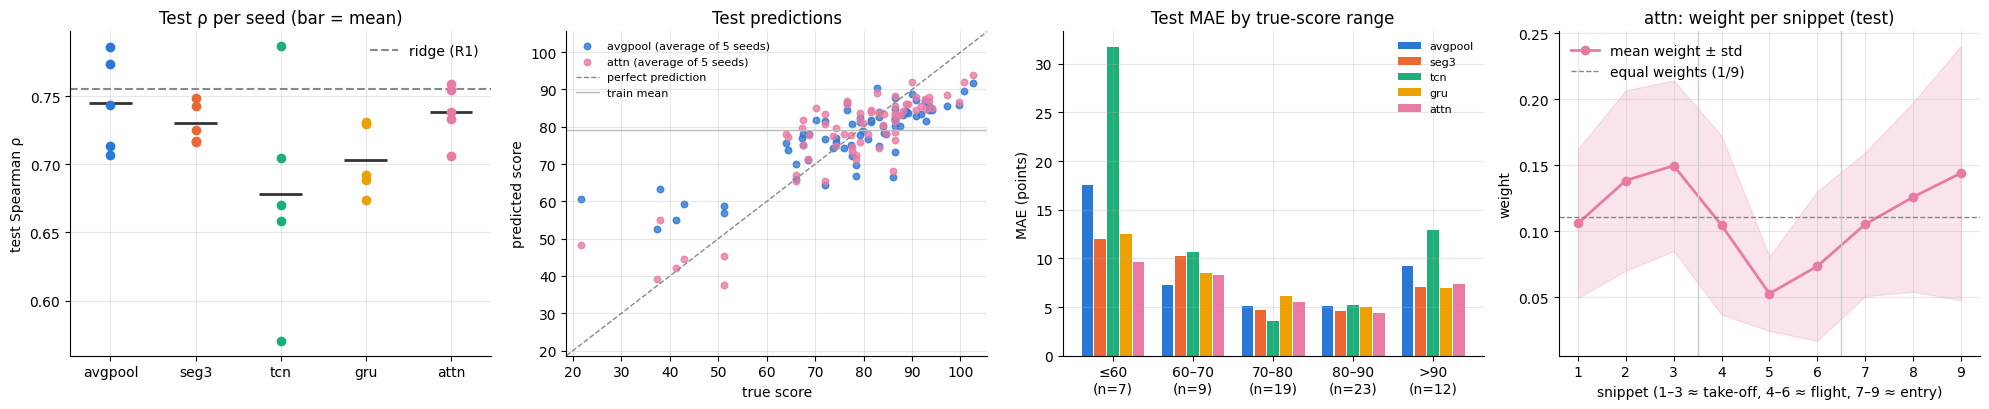

In [21]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
best_temporal = final[final.model != "avgpool"].groupby("model").val_rho.mean().idxmax()
print("temporal model with best mean validation rho:", best_temporal)

fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for i, agg in enumerate(MODELS):                                    
    v = final[final.model == agg].test_rho
    ax[0].scatter(np.full(len(v), i), v, s=36, color=COLORS[agg], zorder=3)
    ax[0].hlines(v.mean(), i - 0.25, i + 0.25, color="#333", lw=2)
ax[0].axhline(metrics(t_test, ridge_test)["rho"], ls="--", color="#888", lw=1.5, label="ridge (R1)")
ax[0].set(xticks=range(len(MODELS)), xticklabels=MODELS, ylabel="test Spearman ρ", title="Test ρ per seed (bar = mean)")
ax[0].legend(frameon=False)

lo, hi = t_test.min() - 3, t_test.max() + 3                          
for agg in ["avgpool", best_temporal]:
    ax[1].scatter(t_test, ENS[agg], s=22, alpha=0.8, color=COLORS[agg], label=f"{agg} (average of 5 seeds)")
ax[1].plot([lo, hi], [lo, hi], color="#888", lw=1, ls="--", label="perfect prediction")
ax[1].axhline(Y_MU, color="#bbb", lw=1, label="train mean")
ax[1].set(xlim=(lo, hi), ylim=(lo, hi), xlabel="true score", ylabel="predicted score", title="Test predictions")
ax[1].legend(frameon=False, fontsize=8)

bins = [0, 60, 70, 80, 90, 200]; lab = ["≤60", "60–70", "70–80", "80–90", ">90"]   
b = pd.cut(t_test, bins, labels=lab); width = 0.8 / len(MODELS)
for i, agg in enumerate(MODELS):
    mae_bin = pd.Series(np.abs(ENS[agg] - t_test)).groupby(b, observed=False).mean()
    ax[2].bar(np.arange(len(lab)) + (i - 2) * width, mae_bin.values, width * 0.9, color=COLORS[agg], label=agg)
cnt = pd.Series(b).value_counts().reindex(lab)
ax[2].set(xticks=range(len(lab)), xticklabels=[f"{l}\n(n={c})" for l, c in zip(lab, cnt)], ylabel="MAE (points)",
          title="Test MAE by true-score range")
ax[2].legend(frameon=False, fontsize=8)

W = np.load(f"{RES_DIR}/attn_weights_test_seed{FINAL_SEEDS[0]}.npy")    
ax[3].plot(range(1, 10), W.mean(0), marker="o", color=COLORS["attn"], lw=2, label="mean weight ± std")
ax[3].fill_between(range(1, 10), W.mean(0) - W.std(0), W.mean(0) + W.std(0), color=COLORS["attn"], alpha=0.2)
ax[3].axhline(1 / 9, color="#888", ls="--", lw=1, label="equal weights (1/9)")
for x in [3.5, 6.5]: ax[3].axvline(x, color="#ccc", lw=1)
ax[3].set(xlabel="snippet (1–3 ≈ take-off, 4–6 ≈ flight, 7–9 ≈ entry)", ylabel="weight", title="attn: weight per snippet (test)")
ax[3].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_part3_results.png", dpi=150); plt.show()

## 3.9 What the results show
**Observed** (Kaggle run, T4 GPU):

| Model | Chosen settings (d, p, lr) | Val ρ | Test ρ (5 seeds) | Test MAE (5 seeds) | Test ρ, average of 5 seeds [CI95] | Test MAE, average of 5 seeds [CI95] |
|---|---|---|---|---|---|---|
| avgpool (baseline) | 128, 0.2, 0.001 | 0.580 | 0.745 ± 0.035 | 7.75 ± 1.09 | 0.776 [0.638, 0.868] | 7.31 [5.96, 8.83] |
| seg3 | 128, 0.2, 0.001 | 0.585 | 0.730 ± 0.015 | 6.60 ± 0.18 | 0.731 [0.583, 0.834] | 6.51 [5.25, 7.91] |
| tcn | 64, 0.5, 0.0003 | 0.593 | 0.678 ± 0.078 | 9.66 ± 1.35 | 0.749 [0.602, 0.847] | 9.43 [7.40, 11.64] |
| gru | 128, 0.5, 0.001 | 0.598 | 0.703 ± 0.026 | 7.26 ± 0.23 | 0.735 [0.580, 0.837] | 6.86 [5.60, 8.38] |
| attn | 128, 0.5, 0.001 | 0.615 | 0.738 ± 0.021 | 6.57 ± 0.42 | 0.766 [0.621, 0.861] | 6.24 [5.16, 7.40] |
| R1 ridge (α = 1000) | – | 0.580 | 0.755 | 9.28 | 0.755 [0.619, 0.852] | 9.28 [7.19, 11.46] |
| R0 mean predictor | – | – | undefined | 11.14 | – | – |

1. **Ranking (ρ):** no temporal model ranks dives better than the baseline or even ridge. All CI95 are about 0.23 wide and overlap almost completely.
2. **Error (MAE):** every learned model beats R0 (11.14). `attn` (6.24) and `seg3` (6.51) have a lower error than the baseline (7.31), and the baseline varies more between seeds (± 1.09 vs ± 0.18–0.42). The intervals overlap, so this table alone does not prove the difference: Part 4 tests it.
3. **Ridge** ranks well (ρ 0.755) but has a large error (9.28). 
4. **Rare low scores are the hardest:** in the ≤ 60 range (7 test dives), every model predicts too high, and above 90 too low.This is caused by the unbalanced scores. `attn` has the smallest error there, `tcn` the largest, but 7 dives is very few to conclude.
5. **tcn is unstable** across seeds (ρ ± 0.078) and has the largest MAE. 
6. **Validation ρ (≈ 0.6) is lower than test ρ (≈ 0.75) for every model, ridge included.** Somewhat expected since we only chose everything using validation. One reason could be the test set has more very low scores (lowest 21.6, std 15.7), which are easy to rank, and 60 validation dives give a noisy ρ. So small differences in validation ρ between models are within noise.
7. **Attention weights** peak on snippets 2–3 (≈ take-off) and 9 (≈ entry) and are lowest on snippet 5 (mid-flight), with large spread. This shows where the model puts weight, **not** what causes its predictions. B ut this honestly could be purely because mid-flight could be very noisy due to the moving camera.

# Part 4 · Task 3 experiment (Option A): does modelling time really help?

**Question (Option A):** does explicit temporal modelling improve quality prediction compared with a global video representation?

**What we compare:** each temporal model (`seg3`, `tcn`, `gru`, `attn`) against the global baseline `avgpool` (average over time). All were trained in Part 3 under identical rules. **Nothing is retrained here**: we reuse the saved test predictions (for each model, the average of its 5 seeds).

**Why Part 3 was not enough:** Part 3 gave each model its own CI95, and the intervals overlapped. But a large part of that width comes from *which* 70 dives are in the test set: some sets of dives are harder for **every** model. That part of the uncertainty says nothing about which model is better.

**Method: paired bootstrap.** "Paired" means both models are always scored on the *same* dives:
1. Draw 70 dives at random, with replacement, from the 70 test dives (one "resample").
2. On this resample compute **MAE(model) − MAE(avgpool)** and **ρ(model) − ρ(avgpool)**. Because both models see exactly the same dives so the hard set of dives effect cancels out.
3. Repeat 2000 times. The middle 95 % of the 2000 differences is the **CI95 of the difference**.

**How to read it:**
- ΔMAE < 0 → the temporal model makes *smaller* errors (better). Δρ > 0 → it *ranks* dives better.
- If the whole interval is on one side of 0, the difference is reliable. If it contains 0, we cannot tell the two models apart.

`attn` had the best *validation* ρ in Part 3, so it is the **main comparison**: *attn has a lower MAE than avgpool* (ΔMAE < 0). The 3 other comparisons are **exploratory** (reported, but weaker evidence).

### Setup and loading the saved predictions


In [22]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr


RES_DIR = os.path.join(OUT, "results")
MODELS = ["avgpool", "seg3", "tcn", "gru", "attn"]; TEMPORAL = ["seg3", "tcn", "gru", "attn"]
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
N_BOOT, BOOT_SEED = 2000, 0

preds = pd.read_csv(os.path.join(RES_DIR, "test_predictions.csv"))       
preds = preds.rename(columns=lambda c: "avgpool_" + c[len("mean_"):] if c.startswith("mean_s") else c)  
seed_cols = lambda m: [c for c in preds.columns if c.startswith(f"{m}_s")]
y_true = preds["y"].to_numpy()
ENS = {m: preds[seed_cols(m)].mean(axis=1).to_numpy() for m in MODELS}  
print("test dives:", len(y_true), "| seeds per model:", {m: len(seed_cols(m)) for m in MODELS})

test dives: 70 | seeds per model: {'avgpool': 5, 'seg3': 5, 'tcn': 5, 'gru': 5, 'attn': 5}


## 4.1 Paired bootstrap
The **same** 2000 resamples  are used for all four comparisons, so the rows can be compared with each other.

Columns of the result table:
- `model vs avgpool`: which temporal model is compared with the baseline.
- `delta_mae`: MAE(model) − MAE(avgpool) on the real 70 test dives, in points. Negative = the model is better.
- `delta_mae_CI95`: 95 % interval of that difference.
- `P(model better, MAE)`: share of the 2000 resamples in which the model had the lower MAE (e.g. 0.99 = in 99 % of them).
- `reliable? (MAE)`: "yes" if the interval does not contain 0.
- `delta_rho`, `delta_rho_CI95`, `P(model better, rho)`, `reliable? (rho)`: the same for Spearman ρ (positive = the model ranks better).

In [23]:
rng = np.random.default_rng(BOOT_SEED)
n = len(y_true)
boot_idx = rng.integers(0, n, size=(N_BOOT, n))                           

def mae(t, p): return np.abs(t - p).mean()
def rho(t, p): return spearmanr(t, p)[0]

base = ENS["avgpool"]
rows, DIST = [], {}
for m in TEMPORAL:
    d_mae = np.array([mae(y_true[i], ENS[m][i]) - mae(y_true[i], base[i]) for i in boot_idx])
    d_rho = np.array([rho(y_true[i], ENS[m][i]) - rho(y_true[i], base[i]) for i in boot_idx])
    DIST[m] = (d_mae, d_rho)
    lo_m, hi_m = np.percentile(d_mae, [2.5, 97.5]); lo_r, hi_r = np.nanpercentile(d_rho, [2.5, 97.5])
    rows.append({
        "model vs avgpool": m + (" (main, chosen on validation)" if m == "attn" else ""),
        "delta_mae": mae(y_true, ENS[m]) - mae(y_true, base),
        "delta_mae_CI95": f"[{lo_m:.2f}, {hi_m:.2f}]",
        "P(model better, MAE)": (d_mae < 0).mean(),
        "reliable? (MAE)": "yes" if hi_m < 0 or lo_m > 0 else "no",
        "delta_rho": rho(y_true, ENS[m]) - rho(y_true, base),
        "delta_rho_CI95": f"[{lo_r:.3f}, {hi_r:.3f}]",
        "P(model better, rho)": (d_rho > 0).mean(),
        "reliable? (rho)": "yes" if hi_r < 0 or lo_r > 0 else "no",
    })
paired = pd.DataFrame(rows)
paired.to_csv(os.path.join(RES_DIR, "task3_paired_bootstrap.csv"), index=False)
paired.round(3)

,model vs avgpool,delta_mae,delta_mae_CI95,"P(model better, MAE)",reliable? (MAE),delta_rho,delta_rho_CI95,"P(model better, rho)",reliable? (rho)
0,seg3,-0.802,"[-1.56, -0.03]",0.978,yes,-0.045,"[-0.113, 0.005]",0.048,no
1,tcn,2.125,"[0.91, 3.30]",0.000,yes,-0.027,"[-0.085, 0.025]",0.166,no
2,gru,-0.449,"[-1.18, 0.26]",0.895,no,-0.041,"[-0.107, 0.011]",0.071,no
3,"attn (main, chosen on validation)",-1.072,"[-2.00, -0.23]",0.994,yes,-0.010,"[-0.060, 0.033]",0.320,no


## 4.2 Figure: the differences and their 95 % intervals
Each dot is the difference measured on the real test set; each bar is its CI95. The dashed line at 0 means "no difference".
- **Left (ΔMAE):** a bar entirely **left of 0** means the temporal model reliably makes smaller errors.
- **Right (Δρ):** a bar entirely **right of 0** means the temporal model reliably ranks dives better.

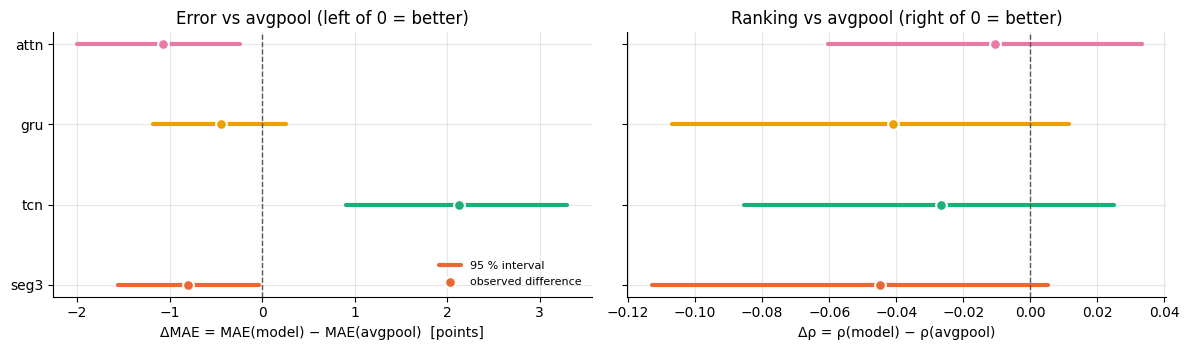

In [24]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for k, (metric, label) in enumerate([(0, "ΔMAE = MAE(model) − MAE(avgpool)  [points]"), (1, "Δρ = ρ(model) − ρ(avgpool)")]):
    for j, m in enumerate(TEMPORAL):
        dist = DIST[m][metric]; lo, hi = np.nanpercentile(dist, [2.5, 97.5])
        obs = paired.iloc[j]["delta_mae" if metric == 0 else "delta_rho"]
        ax[k].plot([lo, hi], [j, j], color=COLORS[m], lw=3, solid_capstyle="round", label="95 % interval" if j == 0 else None)
        ax[k].scatter([obs], [j], color=COLORS[m], s=60, zorder=3, edgecolor="white", linewidth=1.5,
                      label="observed difference" if j == 0 else None)
    ax[k].axvline(0, color="#555", ls="--", lw=1)
    ax[k].set(xlabel=label, yticks=range(len(TEMPORAL)), yticklabels=TEMPORAL)
ax[0].set_title("Error vs avgpool (left of 0 = better)")
ax[1].set_title("Ranking vs avgpool (right of 0 = better)")
ax[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(RES_DIR, "fig_task3_paired_bootstrap.png"), dpi=150); plt.show()

## 4.3 What the experiment shows
**Observed** (Kaggle run):

| Model vs avgpool | ΔMAE (points) [CI95] | P(better, MAE) | Δρ [CI95] | P(better, ρ) |
|---|---|---|---|---|
| **attn (main)** | **−1.07 [−2.00, −0.23]** | 0.994 | −0.010 [−0.060, 0.033] | 0.32 |
| seg3 | −0.80 [−1.56, −0.03] | 0.978 | −0.045 [−0.113, 0.005] | 0.05 |
| gru | −0.45 [−1.18, 0.26] | 0.895 | −0.041 [−0.107, 0.011] | 0.07 |
| tcn | +2.13 [+0.91, +3.30] | 0.000 | −0.027 [−0.085, 0.025] | 0.17 |

1. **Main hypothesis supported:** `attn` makes reliably smaller errors than average pooling, about **1.1 points less** (MAE 7.31 → 6.24, about 15 % lower). The whole interval is below 0, and attn wins in 99.4 % of the resamples.
2. **Ranking is not improved:** no temporal model ranks dives better. Every Δρ interval contains 0, and all the measured differences are slightly negative.
3. **Exploratory comparisons:** `seg3` also has a lower error, but its interval almost touches 0 (−0.03), and it is one of several comparisons, so we treat it as *suggestive* only. `gru`: no reliable difference. `tcn` is **reliably worse** (+2.1 points), in line with its instability in Part 3.

**Answer to the research question:** explicit temporal modelling *can* help, but only in one way. Attention with position information reduced the average error by about 1 point compared with the time-averaged representation, but did **not** rank dives better. And not every temporal model helps: the temporal convolution was worse.

**Our interpretation:** a lower error without a better ranking suggests that `attn` puts its predictions on a more accurate scale (less pulled towards the average score), rather than being better at telling good dives from bad ones. This agrees with Part 3, where attn had the smallest error on the rare low-score dives.

**Limitations:**
- **We don't know if the gain comes from the order in time.** `attn` differs from `avgpool` in several ways (learned weights, position signal, different chosen settings). Separating them would need a control where the snippets are shuffled, which was not run.
- **Small test set (70 dives):** "no difference" in ρ may mean "a difference too small to detect".
- **The bootstrap covers only the choice of test dives.** Seed randomness is reduced by averaging 5 seeds, but is not inside the interval.
- **Several comparisons:** with 4 comparisons, one could look reliable by chance. That is why only attn was fixed in advance as the main comparison.
- **Coarse time and frozen features:** 9 snippets of about 0.5 s each, and I3D already mixes time inside each snippet.
